In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import cmocean

import cartopy.crs as ccrs
from nese.verify.maps import draw_cells
from nese.verify.data import open_anemoi_dataset

In [2]:
from importlib.resources import files
plt.style.use(files("nese.verify") / "nese.mplstyle")

In [6]:
ds = open_anemoi_dataset("anemoi-hpx8-06h/dataset.zarr")
ds824 = open_anemoi_dataset("anemoi-hpx8-24h/dataset.zarr")
ds6 = open_anemoi_dataset("anemoi-hpx6-24h/dataset.zarr")

In [7]:
thedate = "2003-05-01T03"
ds = ds.sel(time=thedate, method="nearest")
ds824 = ds824.sel(time=thedate, method="nearest")
ds6 = ds6.sel(time=thedate, method="nearest")

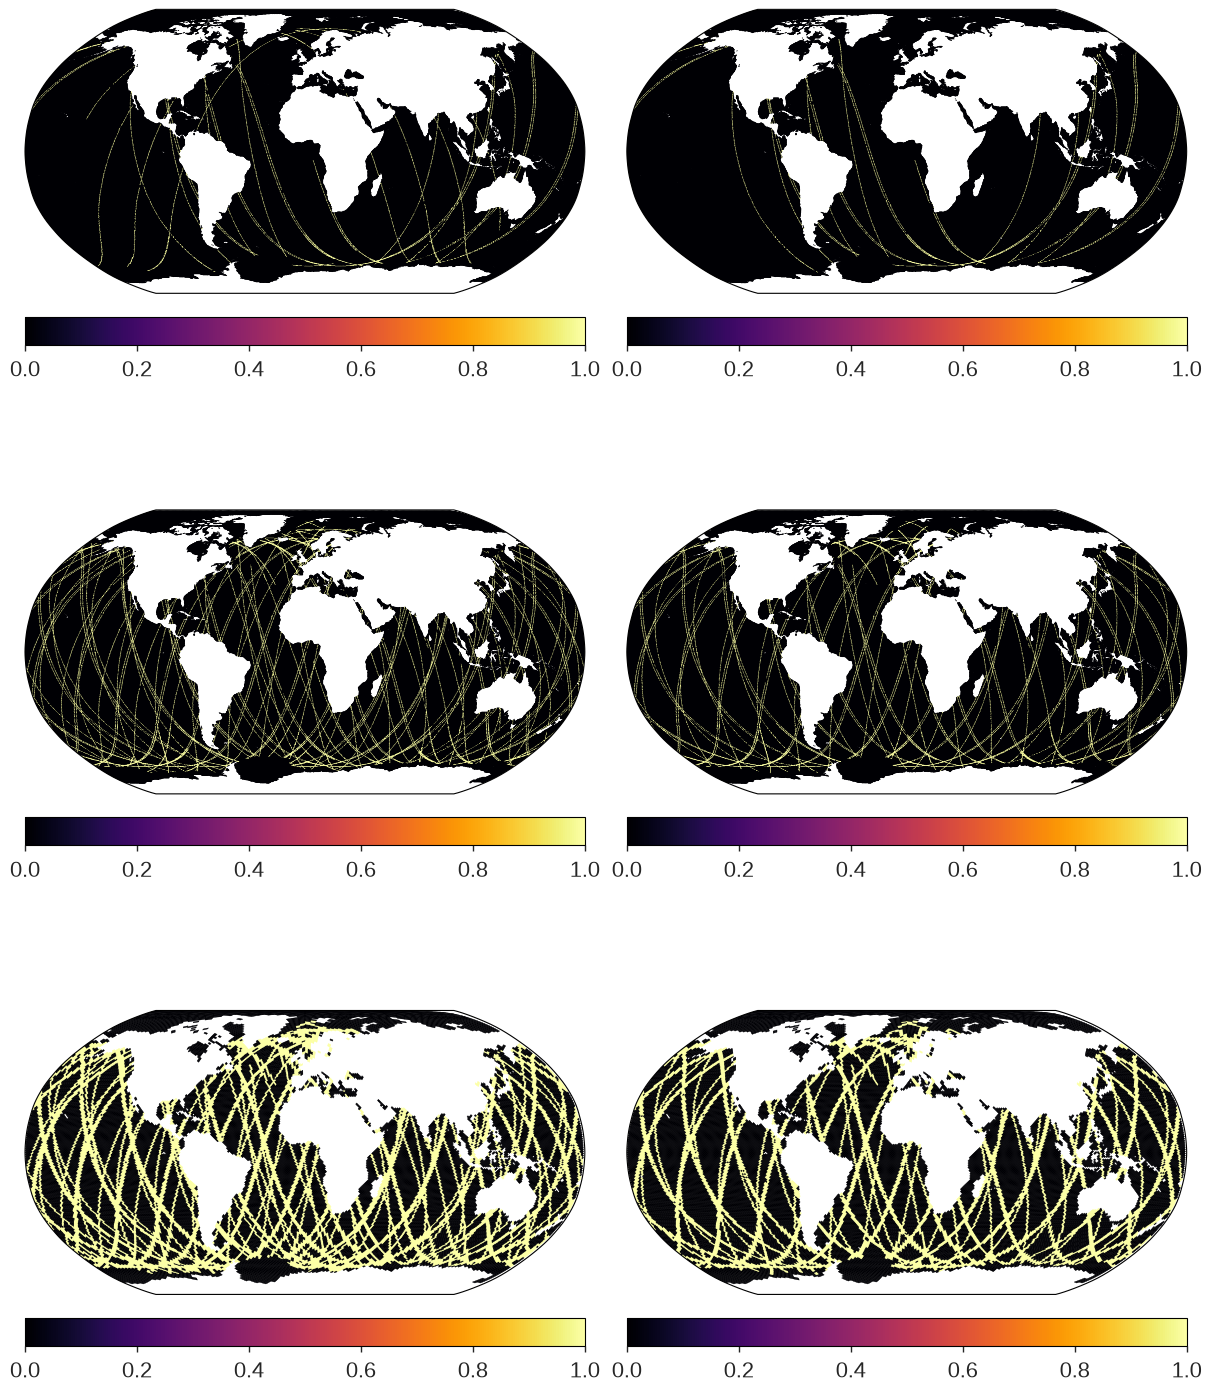

In [8]:
dslist = [ds, ds824, ds6]
nrows = len(dslist)
fig, axs = plt.subplots(nrows, 2, figsize=(12, 5*nrows), subplot_kw={"projection":ccrs.Robinson()})

group = "jason_1"

vmax = {
    f"sla_filtered": .5,
    f"ugxt": .8,
    "swh": 5,
}

for xds, axr in zip(dslist, axs):
    for fieldname, ax in zip([f"sla_filtered", f"swh"], axr): 
        plotme = xr.zeros_like(xds["sla_filtered_jason_2"])
        allvars = [x for x in xds.data_vars if fieldname in x and "count" in x]
        for vname in allvars:
            plotme += xds[vname]
        p = draw_cells(
            ax,
            plotme>0,
            xds.attrs,
            #vmax=vmax[fieldname],
            #vmin=-vmax[fieldname] if "swh" not in fieldname else 0,
            #cmap="cmo.balance",
        )
        plt.colorbar(p, ax=ax, orientation="horizontal")

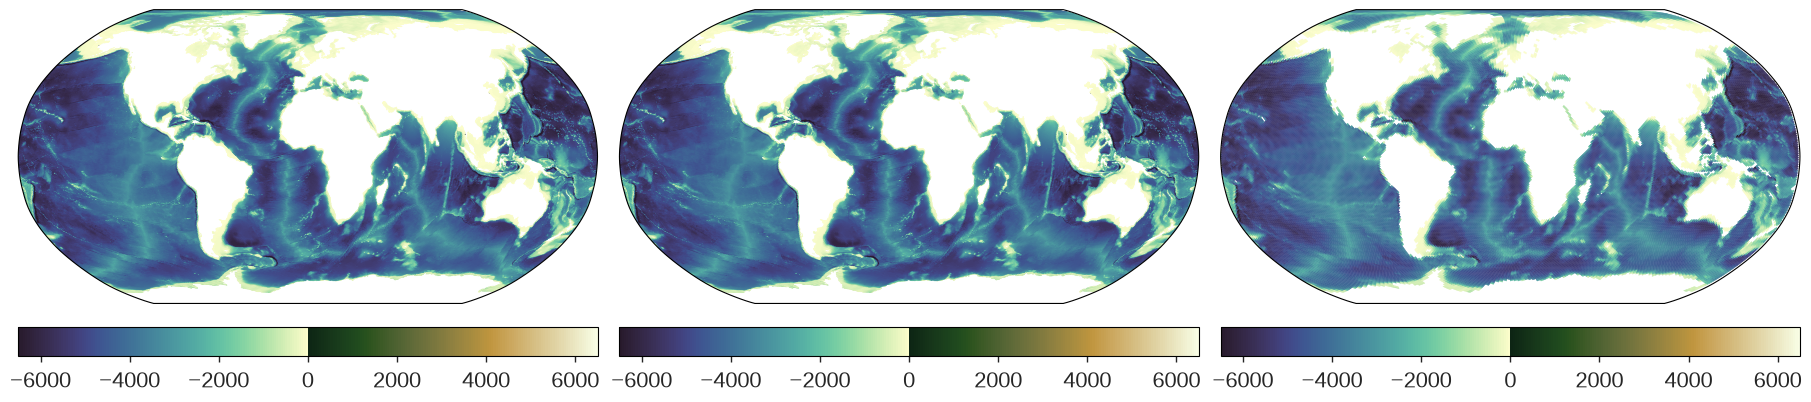

In [9]:
dslist = [ds, ds824, ds6]
ncols = len(dslist)
fig, axs = plt.subplots(1, ncols, figsize=(6*ncols, 5), subplot_kw={"projection":ccrs.Robinson()})

for xds, ax in zip(dslist, axs):
    plotme = xds["elevation"]
    p = draw_cells(
        ax,
        plotme,
        xds.attrs,
        vmax=6500,
        vmin=-6500,
        cmap="cmo.topo",
    )
    plt.colorbar(p, ax=ax, orientation="horizontal")

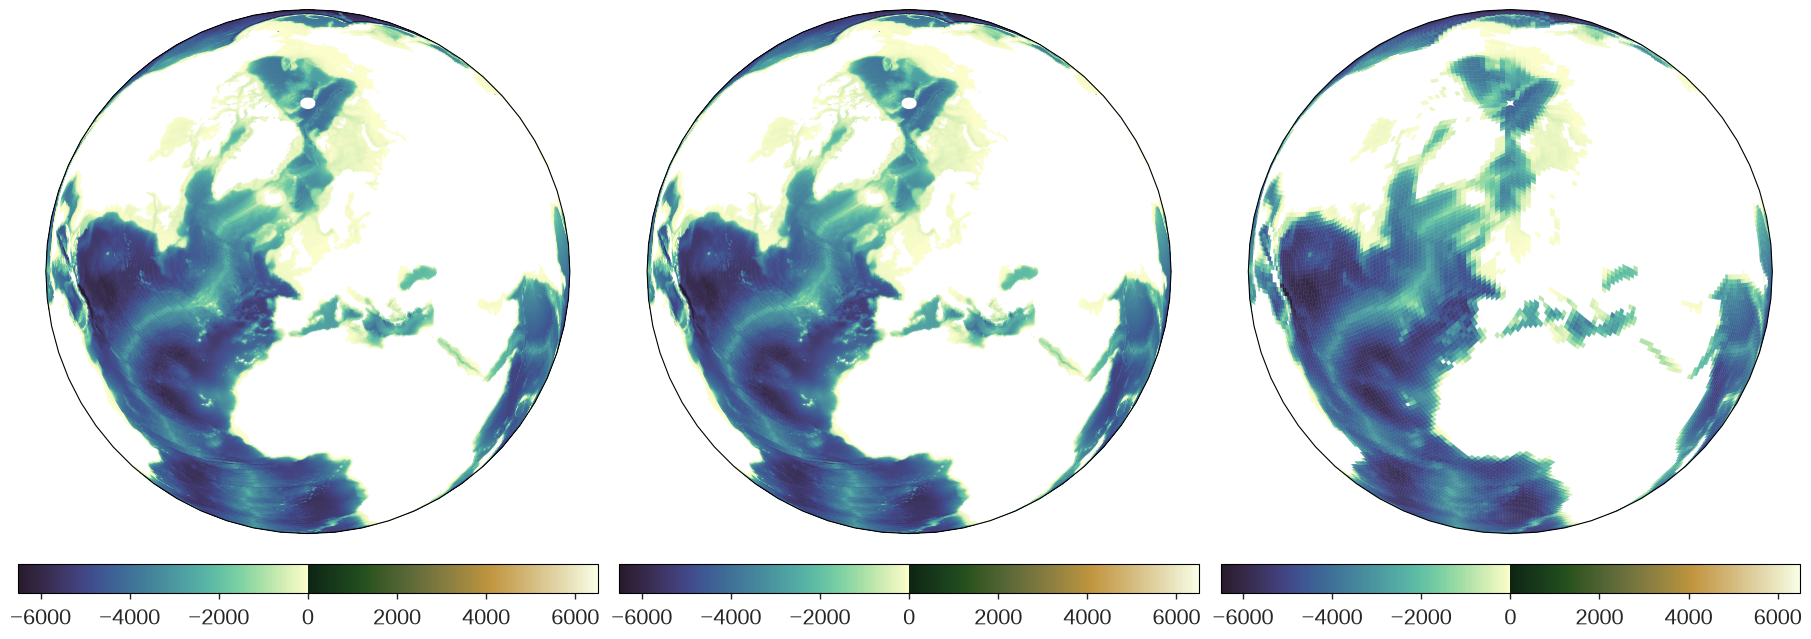

In [10]:
dslist = [ds, ds824, ds6]
nrows = 1
ncols = len(dslist)
fig, axs = plt.subplots(1, ncols, figsize=(6*ncols,6.25*nrows), subplot_kw={"projection": ccrs.Orthographic(0, 50)})
                        
for xds, ax in zip(dslist, axs):
    plotme = xds["elevation"]
    p = draw_cells(
        ax,
        plotme,
        xds.attrs,
        vmax=6500,
        vmin=-6500,
        cmap="cmo.topo",
    )
    plt.colorbar(p, ax=ax, orientation="horizontal")